**Human Movement Intelligence | Presented by: Reza Saadatyar (2026)**

**05 | Classical ML Baselines: HARTH Activity Classification**

![Stage 05 scientific workflow](../../images/05_workflow.svg)

**Objective:** Compare Dummy, Logistic Regression and Random Forest classifiers using participant-disjoint Train and Validation data from eight HARTH recordings.

**Dataset:** Eight selected participants from the pinned HARTH v2.0 release, using label-pure, two-second accelerometer windows and 30 statistical features.

**Notebook Scope:** Evaluate eight documented activity codes (1–8) on Validation only, inspect class-specific errors and retain the exploratory Test partition without scoring it. Other source labels are excluded after windowing and reported separately. This pilot is not the later full Development benchmark.

**01. Imports and Environment**

In [1]:
# ======================== 01. Imports and Environment ========================

# ------ 1. Import standard-library modules for portable project paths. -------
import sys
from pathlib import Path

# ------- 2. Import NumPy and pandas for participant-level data tables. -------
import numpy as np
import pandas as pd

# ----------- 3. Import Matplotlib and notebook display utilities. ------------
import matplotlib.pyplot as plt
from IPython.display import display

# -------------- 4. Import the confusion matrix display helper. ---------------
from sklearn.metrics import ConfusionMatrixDisplay

# -------- 5. Locate repository root without hard-coded machine paths. --------
root = Path.cwd().resolve()
while not (root / "python_modules/core/data_loading.py").is_file():
    if root == root.parent: raise RuntimeError("Notebook must run within the repository.")
    root = root.parent

# ------- 6. Make shared and HARTH-specific Python modules importable. --------
sys.path.insert(0, str(root / "python_modules"))
sys.path.insert(0, str(root / "wearable_activity_recognition/code/src"))

# -------- 7. Import original HARTH readers and reusable ML functions. --------
from harth_data import ACTIVITY_NAMES, ensure_harth_sample, load_harth_subject
from core.signal_preprocessing import create_signal_windows
from core.feature_engineering import extract_signal_features
from core.data_splitting import split_group_indices
from core.ml_baselines import (
    train_validation_classifiers, classification_class_report,
    classification_confusion,
)

# -------------- 8. Apply the approved academic plotting style. ---------------
from core.plot_style import plot_style
plot_style()

# ------ 9. Confirm that the required baseline utilities are available. -------
print("Shared ML utilities imported successfully")

Shared ML utilities imported successfully


**02. Prepare Source Features from Eight HARTH Participants**

Use the same participant list, two-second windowing protocol and deterministic features as Notebook 04. Preserve undocumented source codes for the label audit before restricting the classification task.

In [2]:
# =============== 02. Prepare Source Features from Eight People ===============

# ---------- 1. Fix the exploratory eight-person participant cohort. ----------
SUBJECTS = ["S023", "S024", "S025", "S027", "S028", "S032", "S034", "S035"]

# ------------- 2. Declare eight documented HARTH activity codes. -------------
TASK_CLASSES = tuple(range(1, 9))

# -------------- 3. Select the ignored local source-data cache. ---------------
DATA_ROOT = root / "data/raw/harth_v2"

# ----- 4. Initialise aligned person-specific feature and metadata lists. -----
feature_parts, metadata_parts = [], []

# -------- 5. Extract windows and features separately for each person. --------
for subject in SUBJECTS:
    source_path = ensure_harth_sample(DATA_ROOT, subject=subject)
    data, channels = load_harth_subject(
        source_path, allow_unmapped_labels=True
    )
    windows, labels, info = create_signal_windows(
        signals=data[channels].to_numpy(),
        labels=data["label"].to_numpy(),
        window_size=100, step_size=50,
        timestamps=data["timestamp"], sampling_rate=50,
        min_label_purity=1.0, subject_id=subject,
    )
    feature_parts.append(extract_signal_features(windows, channel_names=channels))
    metadata_parts.append(info)

# ------- 6. Join per-person feature matrices without losing row order. -------
features_all = pd.concat(feature_parts, ignore_index=True)

# --------- 7. Concatenate aligned window provenance for all people. ----------
metadata_all = pd.concat(metadata_parts, ignore_index=True)

# ---------- 8. Confirm one metadata row per extracted feature row. -----------
assert len(features_all) == len(metadata_all)

# ------ 9. Report complete source feature shape before task filtering. -------
print("Complete source feature matrix:", features_all.shape)

Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S023.csv
HARTH subject S023: 137,646 rows, 6 sensors
Input signal: 137,646 samples, 6 channels
Candidate windows: 2,751
Retained windows: 2,567 | Shape: (2567, 6, 100)
Rejected candidates: 184
Input windows: (2567, 6, 100)
Feature matrix: (2567, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S024.csv
HARTH subject S024: 170,534 rows, 6 sensors
Input signal: 170,534 samples, 6 channels
Candidate windows: 3,409
Retained windows: 3,119 | Shape: (3119, 6, 100)
Rejected candidates: 290
Input windows: (3119, 6, 100)
Feature matrix: (3119, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S025.csv
HARTH subject S025: 231,729 rows, 6 sensors
Input signal: 231,729 samples, 6 channels
Candidate windows: 4,633
Retained windows: 4,272 | Shape: (4272, 6, 1

C:\Users\Reza\AppData\Local\Temp\ipykernel_416\4116255968.py:18: UserWarning: Unexpected HARTH activity codes: [10, 11] (2,018 rows in S032.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S032: 178,341 rows, 6 sensors
Input signal: 178,341 samples, 6 channels
Candidate windows: 3,565
Retained windows: 3,038 | Shape: (3038, 6, 100)
Rejected candidates: 527
Input windows: (3038, 6, 100)
Feature matrix: (3038, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S034.csv
HARTH subject S034: 188,202 rows, 6 sensors
Input signal: 188,202 samples, 6 channels
Candidate windows: 3,763
Retained windows: 3,351 | Shape: (3351, 6, 100)
Rejected candidates: 412
Input windows: (3351, 6, 100)
Feature matrix: (3351, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S035.csv
HARTH subject S035: 181,251 rows, 6 sensors
Input signal: 181,251 samples, 6 channels
Candidate windows: 3,624
Retained windows: 3,337 | Shape: (3337, 6, 100)
Rejected candidates: 287
Input windows: (3337, 6, 100)
Feature matrix: (3337, 3

**03. Restrict the Cohort to Eight Documented Activities**

Retain published HARTH codes 1–8 after time-safe windowing. Report excluded codes and participant-level support without joining otherwise separate source intervals.

In [3]:
# ============== 03. Restrict to the Documented Eight-Class Task ==============

# ------ 1. Audit source label frequencies separately for every person. -------
raw_class_counts = (
    metadata_all.groupby(["subject_id", "label"])
    .size().rename("windows").reset_index()
)

# ------- 2. Identify each documented code and mark undocumented ones. --------
raw_class_counts["activity"] = raw_class_counts["label"].map(
    lambda value: ACTIVITY_NAMES.get(int(value), "UNDOCUMENTED")
)

# ---------- 3. Explicitly flag classes inside the predefined task. -----------
raw_class_counts["in_task"] = raw_class_counts["label"].isin(TASK_CLASSES)

# --------- 4. Display source label provenance before any exclusions. ---------
display(raw_class_counts)

# -------- 5. Apply the task filter after time-safe source windowing. ---------
included = metadata_all["label"].isin(TASK_CLASSES).to_numpy()

# ------------- 6. Count removed windows by original label code. --------------
excluded = metadata_all.loc[~included, "label"].value_counts().sort_index()

# -------- 7. Preserve aligned feature and label rows after filtering. --------
features = features_all.loc[included].reset_index(drop=True)
metadata = metadata_all.loc[included].reset_index(drop=True)

# ------- 8. Report exclusions and the actual eight-class matrix size. --------
print("Excluded windows by source code:", excluded.to_dict())
print("Eight-class feature matrix:", features.shape)

,subject_id,label,windows,activity,in_task
0,S023,1,1352,Walking,True
1,S023,2,441,Running,True
2,S023,3,7,Shuffling,True
3,S023,4,42,Stairs ascending,True
4,S023,5,26,Stairs descending,True
5,S023,6,114,Standing,True
6,S023,7,257,Sitting,True
7,S023,8,328,Lying,True
8,S024,1,1492,Walking,True
9,S024,2,511,Running,True


Excluded windows by source code: {10: 1, 13: 1018, 14: 238, 130: 78, 140: 65}
Eight-class feature matrix: (24563, 30)


**04. Create Participant-Disjoint Train/Validation/Test Splits**

Reproduce the fixed-seed eight-participant split from Notebook 04. Train and Validation are used for model comparison; the exploratory Test partition is reserved and not scored.

**Protocol distinction:** These groups precede the later 29-person Development protocol and qualified held-out evaluation.

In [4]:
# ================ 04. Create Subject-Disjoint Data Partitions ================

# -------- 1. Split entire participant IDs with the unchanged seed 42. --------
partitions = split_group_indices(
    metadata["subject_id"].to_numpy(),
    train_fraction=0.50, validation_fraction=0.25,
    test_fraction=0.25, random_state=42,
)

# ----------- 2. Build original subject-ID sets for each partition. -----------
group_sets = {
    part: set(metadata.iloc[idx]["subject_id"])
    for part, idx in partitions.items()
}

# ------ 3. Assert no participant overlaps between Train and Validation. ------
assert not (group_sets["train"] & group_sets["validation"])
assert not (group_sets["train"] & group_sets["test"])
assert not (group_sets["validation"] & group_sets["test"])

# ----------- 4. Display the full 4/2/2 exploratory split coverage. -----------
display(pd.DataFrame([
    {"partition":part,"subjects":", ".join(sorted(group_sets[part])),
     "windows":len(idx)}
    for part,idx in partitions.items()
]))

# -------- 5. Select Train and Validation rows only for model fitting. --------
train_ids, validation_ids = partitions["train"], partitions["validation"]
X_train = features.iloc[train_ids]
y_train = metadata.iloc[train_ids]["label"].to_numpy()
X_validation = features.iloc[validation_ids]
y_validation = metadata.iloc[validation_ids]["label"].to_numpy()

# ----------- 6. Audit eight-class support on Train and Validation. -----------
coverage = pd.DataFrame({
    "train": pd.Series(y_train).value_counts(),
    "validation": pd.Series(y_validation).value_counts(),
}).reindex(TASK_CLASSES, fill_value=0).fillna(0).astype(int)
coverage.index = [ACTIVITY_NAMES[c] for c in TASK_CLASSES]

# ---------- 7. Show the actual class-support table before fitting. -----------
display(coverage)
assert (coverage["train"] > 0).all(), "Not every defined task class is in Train."

# ----------- 8. Confirm no Test inference or model selection here. -----------
print("Held-out test partition: reserved, not inspected for modelling")

Independent groups: 8
train: 4 groups | 12,489 rows
validation: 2 groups | 6,470 rows
test: 2 groups | 5,604 rows


,partition,subjects,windows
0,train,"S025, S027, S028, S035",12489
1,validation,"S024, S034",6470
2,test,"S023, S032",5604


,train,validation
Walking,6053,2009
Running,3283,511
Shuffling,91,58
Stairs ascending,76,82
Stairs descending,54,65
Standing,700,1219
Sitting,1039,1547
Lying,1193,979


Held-out test partition: reserved, not inspected for modelling


**05. Train and Compare the Three Validation Baselines**

Compare a majority-class DummyClassifier, Train-scaled Logistic Regression and unscaled Random Forest. Use Macro F1 as the main model-selection metric, with all preprocessing fitted on Train only.

In [5]:
# ================ 05. Train and Compare Validation Baselines =================

# ------- 1. Train Dummy, Logistic Regression and RF using Train only. --------
models, comparison, predictions = train_validation_classifiers(
    X_train, y_train, X_validation, y_validation,
    classes=TASK_CLASSES, random_state=42,
)

# ------------- 2. Display all three Validation score summaries. --------------
display(comparison.style.format({
    name:"{:.3f}" for name in comparison.columns if name != "model"
}))

# ------ 3. Select the exploratory reference using Validation Macro F1. -------
best_name = comparison.loc[0, "model"]

# ------ 4. Report the selected Validation model, not Test performance. -------
print("Best validation Macro F1:", best_name)

# ------------- 5. Confirm the reserved Test set was not scored. --------------
print("Final Test evaluated: NO")

Dummy (most frequent): Validation Macro F1 = 0.0592
Logistic Regression: Validation Macro F1 = 0.8343
Random Forest: Validation Macro F1 = 0.7563


,model,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1
0,Logistic Regression,0.949,0.893,0.830,0.893,0.834
1,Random Forest,0.970,0.736,0.883,0.736,0.756
2,Dummy (most frequent),0.311,0.125,0.039,0.125,0.059


Best validation Macro F1: Logistic Regression
Final Test evaluated: NO


**06. Compare Validation Metrics Visually**

Plot Macro F1 and balanced accuracy from the same held-out Validation participants. The scores describe this exploratory split, not external or final Test performance.

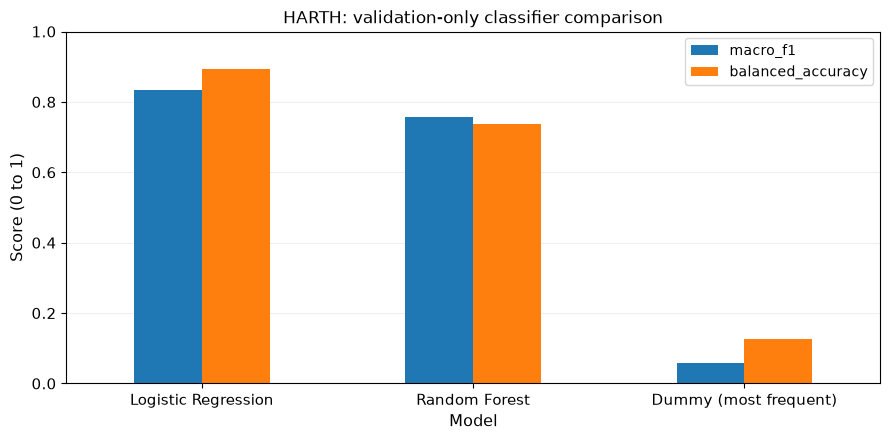

In [6]:
# ================== 06. Compare Validation Metrics Visually ==================

# ------- 1. Compare Macro F1 and balanced accuracy on the same people. -------
plot_table = comparison.set_index("model")[["macro_f1", "balanced_accuracy"]]

# -------------- 2. Draw the original grouped metric comparison. --------------
ax = plot_table.plot(kind="bar", figsize=(9, 4.5), rot=0)
ax.set(title="HARTH: validation-only classifier comparison",
       xlabel="Model", ylabel="Score (0 to 1)", ylim=(0, 1))
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

**07. Inspect Per-Class Errors of the Selected Validation Model**

Examine per-class precision, recall, F1 and the confusion matrix for the Validation-selected model to identify activity-specific errors.

,class,support,precision,recall,f1
0,Walking,2009,0.977898,0.902937,0.938923
1,Running,511,1.000000,0.994129,0.997056
2,Shuffling,58,0.239819,0.913793,0.379928
3,Stairs ascending,82,0.514851,0.634146,0.568306
4,Stairs descending,65,0.960784,0.753846,0.844828
5,Standing,1219,0.946414,0.985234,0.965434
6,Sitting,1547,1.000000,0.960569,0.979888
7,Lying,979,1.000000,1.000000,1.000000


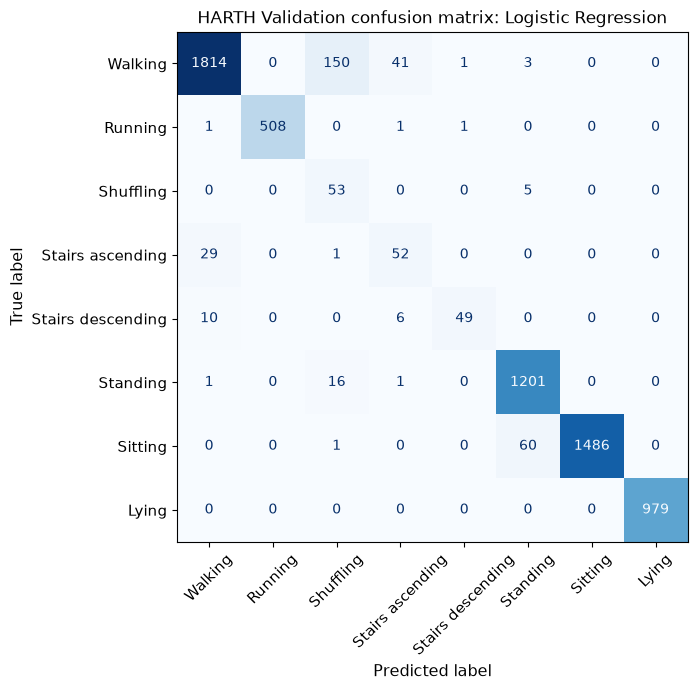

In [7]:
# ================= 07. Inspect Validation Class-Level Errors =================

# ----- 1. Retrieve predictions from the Validation-selected classifier. ------
best_predictions = predictions[best_name]

# --------- 2. Preserve all eight official activity names and order. ----------
class_names = [ACTIVITY_NAMES[code] for code in TASK_CLASSES]

# -------- 3. Calculate fixed-code precision, recall and F1 by class. ---------
class_report = classification_class_report(
    y_validation, best_predictions,
    classes=TASK_CLASSES, class_names=class_names,
)

# -------- 4. Display per-class Validation results and actual support. --------
display(class_report)

# --------- 5. Build the corresponding eight-class confusion matrix. ----------
matrix = classification_confusion(
    y_validation, best_predictions, classes=TASK_CLASSES
)

# --------- 6. Plot class-level errors for Validation subjects only. ----------
fig, ax = plt.subplots(figsize=(9, 7))
ConfusionMatrixDisplay(
    confusion_matrix=matrix, display_labels=class_names
).plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
ax.set_title(f"HARTH Validation confusion matrix: {best_name}")
plt.tight_layout()
plt.show()

**08. Exploratory Baseline Quality Gate**

Verify feature integrity, participant separation, the predefined eight-class target and the absence of Test scoring. Interpret the model comparison within this exploratory Validation protocol; the remaining HARTH participants and independent evaluation are outside its scope.


In [8]:
# =================== 08. Exploratory Baseline Quality Gate ===================

# -------- 1. Confirm 30 features and finite Train/Validation values. ---------
assert X_train.shape[1] == X_validation.shape[1] == 30
assert np.isfinite(X_train.to_numpy()).all()
assert np.isfinite(X_validation.to_numpy()).all()

# --------- 2. Recheck participant-independent Train/Validation sets. ---------
assert not (group_sets["train"] & group_sets["validation"])

# ----------- 3. Verify all three predeclared baseline model rows. ------------
assert len(comparison) == 3
assert comparison["macro_f1"].between(0, 1).all()

# --------- 4. Report original Train and Validation participant IDs. ----------
print("Train subject IDs:", sorted(group_sets["train"]))
print("Validation subject IDs:", sorted(group_sets["validation"]))

# -------- 5. Record approved class definitions and excluded windows. ---------
print("Defined classification task:", [ACTIVITY_NAMES[c] for c in TASK_CLASSES])
print("Undocumented/source-excluded windows:", int((~included).sum()))

# --------- 6. Confirm Test data were not used for model assessment. ----------
print("Final Test model inference performed: NO")

# -------- 7. Summarise the scientific boundary and successful checks. --------
print("Exploratory validation baseline: PASSED")

Train subject IDs: ['S025', 'S027', 'S028', 'S035']
Validation subject IDs: ['S024', 'S034']
Defined classification task: ['Walking', 'Running', 'Shuffling', 'Stairs ascending', 'Stairs descending', 'Standing', 'Sitting', 'Lying']
Undocumented/source-excluded windows: 1400
Final Test model inference performed: NO
Exploratory validation baseline: PASSED
